
# NLP Project 1 — Parts 1 and 2
## Interpretability of Model Collapse

This notebook contains only the implementation required for:

**Part 1.** Implement a transformer architecture to learn induction heads on the in-context learning symbol task.

**Part 2.** Incorporate model collapse into the pipeline, including both:
- the **base task**: predict the label corresponding to the query symbol;
- the **extended task**: predict the query label, the next symbol, and that symbol's label.

The notebook intentionally excludes the later mechanistic-interpretability analysis and report-writing sections.


## 0. Imports and reproducibility

In [1]:

import math
import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cpu



# Part 1 — Transformer for the induction-head in-context learning task

Each episode samples a new symbol-to-label mapping. Because the mapping changes from one episode to another, the model cannot solve the task by memorising a global lookup table. It must infer the relationship from examples in the current context.

Prompt format:

\[
[\mathrm{BOS},s_1,\ell(s_1),s_2,\ell(s_2),\ldots,s_k,\ell(s_k),\mathrm{SEP},q]
\]

For the **base task**, the target is:

\[
[\ell(q)]
\]

where \(q\) is guaranteed to have appeared in the context.


## 1.1 Task configuration and synthetic dataset

In [2]:

@dataclass
class TaskConfig:
    n_symbols: int = 8
    n_labels: int = 8
    n_context_pairs: int = 6
    mode: str = "base"  # "base" or "extended"

    @property
    def label_offset(self):
        return self.n_symbols

    @property
    def bos_id(self):
        return self.n_symbols + self.n_labels

    @property
    def sep_id(self):
        return self.bos_id + 1

    @property
    def vocab_size(self):
        return self.sep_id + 1

    @property
    def target_len(self):
        return 1 if self.mode == "base" else 3


class ICLEpisodeDataset(Dataset):
    def __init__(self, n_samples, cfg, seed=0):
        self.n_samples = n_samples
        self.cfg = cfg
        self.seed = seed
        self.examples = [self._make_example(i) for i in range(n_samples)]

    def _make_example(self, idx):
        rng = np.random.default_rng(self.seed + idx)
        cfg = self.cfg

        symbols = np.arange(cfg.n_symbols)
        labels = np.arange(cfg.n_labels)

        # Fresh one-to-one mapping for every episode.
        perm = rng.permutation(labels)[:cfg.n_symbols]
        mapping = {int(s): int(perm[s]) for s in symbols}

        # Repeated symbols are allowed in the context.
        context_syms = rng.choice(
            symbols, size=cfg.n_context_pairs, replace=True
        )

        # Query is guaranteed to occur in the context.
        q = int(rng.choice(context_syms))

        # Only used by the extended version.
        next_s = int(rng.choice(symbols))

        prompt = [cfg.bos_id]
        for s in context_syms:
            prompt.extend([
                int(s),
                cfg.label_offset + mapping[int(s)]
            ])
        prompt.extend([cfg.sep_id, q])

        if cfg.mode == "base":
            target = [cfg.label_offset + mapping[q]]
        else:
            target = [
                cfg.label_offset + mapping[q],
                next_s,
                cfg.label_offset + mapping[next_s],
            ]

        metadata = {
            "mapping": mapping,
            "context_symbols": [int(x) for x in context_syms],
            "query_symbol": q,
            "query_label": mapping[q],
            "next_symbol": next_s,
            "next_label": mapping[next_s],
        }

        return (
            torch.tensor(prompt, dtype=torch.long),
            torch.tensor(target, dtype=torch.long),
            metadata,
        )

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        return self.examples[idx]


def collate_batch(batch):
    prompts = torch.stack([x[0] for x in batch])
    targets = torch.stack([x[1] for x in batch])
    metadata = [x[2] for x in batch]
    return prompts, targets, metadata


### Inspect one base-task episode

In [3]:

base_cfg = TaskConfig(mode="base")
demo_ds = ICLEpisodeDataset(3, base_cfg, seed=SEED)

prompt, target, meta = demo_ds[0]

print("Prompt token IDs :", prompt.tolist())
print("Target token IDs :", target.tolist())
print("Context symbols  :", meta["context_symbols"])
print("Episode mapping  :", meta["mapping"])
print("Query symbol     :", meta["query_symbol"])
print("Correct label    :", meta["query_label"])


Prompt token IDs : [16, 5, 9, 1, 12, 0, 11, 4, 14, 7, 8, 5, 9, 17, 7]
Target token IDs : [8]
Context symbols  : [5, 1, 0, 4, 7, 5]
Episode mapping  : {0: 3, 1: 4, 2: 2, 3: 7, 4: 6, 5: 1, 6: 5, 7: 0}
Query symbol     : 7
Correct label    : 0


## 1.2 Decoder-only causal transformer

In [4]:

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model=128, n_heads=4, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0

        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

        # Stored for later project parts if needed.
        self.last_attn = None

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)

        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        causal_mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )
        scores = scores.masked_fill(causal_mask, float("-inf"))

        attn = torch.softmax(scores, dim=-1)
        self.last_attn = attn.detach()

        attn = self.dropout(attn)
        y = attn @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.out(y)


class TransformerBlock(nn.Module):
    def __init__(self, d_model=128, n_heads=4, d_ff=256, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, dropout)

        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class TinyTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        max_len,
        target_len,
        d_model=128,
        n_heads=4,
        n_layers=2,
        d_ff=256,
        dropout=0.1,
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.target_len = target_len

        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(
            max_len + target_len + 2, d_model
        )

        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        self.final_ln = nn.LayerNorm(d_model)
        self.output_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, tokens):
        B, T = tokens.shape

        positions = torch.arange(
            T, device=tokens.device
        ).unsqueeze(0)

        x = (
            self.token_embedding(tokens)
            + self.position_embedding(positions)
        )

        for block in self.blocks:
            x = block(x)

        x = self.final_ln(x)
        return self.output_head(x)

    @torch.no_grad()
    def generate(self, prompt, n_tokens):
        output = prompt

        for _ in range(n_tokens):
            logits = self(output)
            next_token = torch.argmax(
                logits[:, -1, :],
                dim=-1,
                keepdim=True,
            )
            output = torch.cat([output, next_token], dim=1)

        return output[:, -n_tokens:]


## 1.3 Training and evaluation functions

In [5]:

def autoregressive_loss(model, prompts, targets):
    """Teacher-forced cross-entropy over target positions only."""
    current_input = prompts
    losses = []

    for j in range(targets.shape[1]):
        logits = model(current_input)[:, -1, :]
        loss_j = nn.functional.cross_entropy(
            logits, targets[:, j]
        )
        losses.append(loss_j)

        current_input = torch.cat(
            [current_input, targets[:, j:j+1]],
            dim=1
        )

    return torch.stack(losses).mean()


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    model.eval()

    total_loss = 0.0
    total_examples = 0
    first_correct = 0
    token_correct = 0
    token_total = 0
    sequence_correct = 0
    all_predictions = []

    for prompts, targets, _ in loader:
        prompts = prompts.to(device)
        targets = targets.to(device)

        loss = autoregressive_loss(model, prompts, targets)
        predictions = model.generate(
            prompts, n_tokens=targets.shape[1]
        )

        batch_size = prompts.size(0)

        total_loss += loss.item() * batch_size
        total_examples += batch_size

        first_correct += (
            predictions[:, 0] == targets[:, 0]
        ).sum().item()

        token_correct += (
            predictions == targets
        ).sum().item()

        token_total += targets.numel()

        sequence_correct += (
            predictions == targets
        ).all(dim=1).sum().item()

        all_predictions.append(predictions.cpu())

    mean_loss = total_loss / max(total_examples, 1)

    predictions = torch.cat(all_predictions, dim=0)
    counts = torch.bincount(
        predictions.flatten(),
        minlength=model.vocab_size
    ).float()

    probabilities = counts / counts.sum().clamp_min(1)
    non_zero = probabilities > 0

    entropy = -(
        probabilities[non_zero]
        * torch.log(probabilities[non_zero])
    ).sum().item()

    return {
        "loss": mean_loss,
        "perplexity": float(math.exp(min(mean_loss, 20))),
        "first_token_accuracy":
            first_correct / max(total_examples, 1),
        "token_accuracy":
            token_correct / max(token_total, 1),
        "sequence_accuracy":
            sequence_correct / max(total_examples, 1),
        "prediction_entropy": entropy,
    }


def train_model(
    model,
    train_loader,
    val_loader,
    epochs=8,
    lr=3e-4,
    weight_decay=1e-4,
    device=DEVICE,
):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    history = []
    best_state = None
    best_val_loss = float("inf")

    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        n_seen = 0

        for prompts, targets, _ in train_loader:
            prompts = prompts.to(device)
            targets = targets.to(device)

            optimizer.zero_grad(set_to_none=True)

            loss = autoregressive_loss(
                model, prompts, targets
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )
            optimizer.step()

            running_loss += loss.item() * len(prompts)
            n_seen += len(prompts)

        train_loss = running_loss / max(n_seen, 1)
        val_metrics = evaluate(
            model, val_loader, device
        )

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            **{
                f"val_{k}": v
                for k, v in val_metrics.items()
            },
        }
        history.append(row)

        print(
            f"Epoch {epoch:02d} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={val_metrics['sequence_accuracy']:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    if best_state is not None:
        model.load_state_dict(best_state)

    return pd.DataFrame(history)



## 1.4 Train Generation 0 on real data

The values below are reasonable starting values. If you are testing the notebook on CPU, reduce `N_TRAIN` and `EPOCHS` first.


In [6]:

# Experiment settings
N_TRAIN = 10_000
N_VAL = 2_000
N_TEST = 2_000

BATCH_SIZE = 128
EPOCHS = 8

D_MODEL = 128
N_HEADS = 4
N_LAYERS = 2
D_FF = 256
DROPOUT = 0.1
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4


In [7]:

cfg = TaskConfig(mode="base")

train_ds = ICLEpisodeDataset(
    N_TRAIN, cfg, seed=SEED
)
val_ds = ICLEpisodeDataset(
    N_VAL, cfg, seed=SEED + 100_000
)
test_ds = ICLEpisodeDataset(
    N_TEST, cfg, seed=SEED + 200_000
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
)

max_prompt_len = 1 + 2 * cfg.n_context_pairs + 2

base_model_gen0 = TinyTransformer(
    vocab_size=cfg.vocab_size,
    max_len=max_prompt_len,
    target_len=cfg.target_len,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF,
    dropout=DROPOUT,
).to(DEVICE)

history_base_gen0 = train_model(
    base_model_gen0,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

base_gen0_test = evaluate(
    base_model_gen0, test_loader
)

print("\nGeneration 0 base-task test metrics:")
display(pd.DataFrame([base_gen0_test]))


Epoch 01 | train loss=2.0949 | val loss=1.6901 | val acc=0.3405
Epoch 02 | train loss=1.6191 | val loss=1.5587 | val acc=0.3585
Epoch 03 | train loss=1.5301 | val loss=1.4906 | val acc=0.3890
Epoch 04 | train loss=0.9477 | val loss=0.0509 | val acc=0.9990
Epoch 05 | train loss=0.0861 | val loss=0.0107 | val acc=1.0000
Epoch 06 | train loss=0.0219 | val loss=0.0054 | val acc=1.0000
Epoch 07 | train loss=0.0133 | val loss=0.0036 | val acc=1.0000
Epoch 08 | train loss=0.0072 | val loss=0.0027 | val acc=1.0000

Generation 0 base-task test metrics:


,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,0.002739,1.002743,1.0,1.0,1.0,2.078498


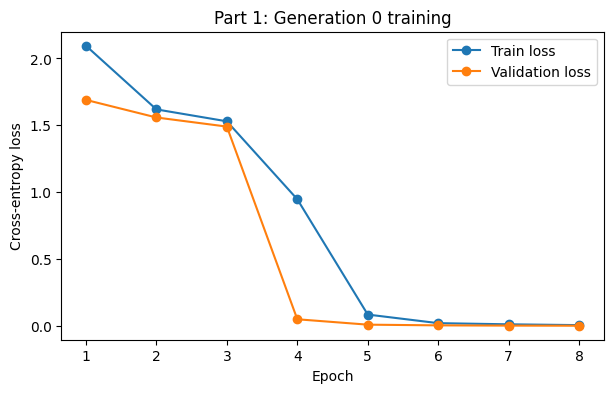

In [8]:

plt.figure(figsize=(7, 4))
plt.plot(
    history_base_gen0["epoch"],
    history_base_gen0["train_loss"],
    marker="o",
    label="Train loss",
)
plt.plot(
    history_base_gen0["epoch"],
    history_base_gen0["val_loss"],
    marker="o",
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Part 1: Generation 0 training")
plt.legend()
plt.show()



# Part 2 — Model collapse pipeline

For generation \(g>0\), a fraction of the original training targets is replaced with predictions generated by the previous-generation model.

The prompts remain fixed, while the target labels increasingly become synthetic.

A simple schedule is:

| Generation | Synthetic fraction |
|---:|---:|
| 0 | 0.00 |
| 1 | 0.25 |
| 2 | 0.50 |
| 3 | 0.75 |
| 4 | 1.00 |

Two experiments are run:
1. **Base** — predict one query label.
2. **Extended** — predict `[query label, next symbol, next-symbol label]`.


## 2.1 Dataset containing recursively generated targets

In [9]:

class TensorEpisodeDataset(Dataset):
    def __init__(self, prompts, targets, metadata=None):
        self.prompts = prompts
        self.targets = targets
        self.metadata = (
            metadata
            if metadata is not None
            else [{} for _ in range(len(prompts))]
        )

    def __len__(self):
        return len(self.prompts)

    def __getitem__(self, idx):
        return (
            self.prompts[idx],
            self.targets[idx],
            self.metadata[idx],
        )


@torch.no_grad()
def make_synthetic_dataset(
    previous_model,
    real_dataset,
    synthetic_fraction,
    device=DEVICE,
    seed=0,
):
    """
    Replace a chosen fraction of gold targets with predictions
    from the previous-generation model.
    """
    rng = np.random.default_rng(seed)

    prompts = torch.stack(
        [real_dataset[i][0] for i in range(len(real_dataset))]
    )
    gold_targets = torch.stack(
        [real_dataset[i][1] for i in range(len(real_dataset))]
    )
    metadata = [
        real_dataset[i][2] for i in range(len(real_dataset))
    ]

    new_targets = gold_targets.clone()

    indices = np.arange(len(real_dataset))
    rng.shuffle(indices)

    n_synthetic = int(
        round(synthetic_fraction * len(indices))
    )
    chosen = indices[:n_synthetic]

    previous_model.eval()

    batch_size = 256

    for start in range(0, n_synthetic, batch_size):
        batch_indices = chosen[start:start + batch_size]

        batch_prompts = prompts[
            batch_indices
        ].to(device)

        predictions = previous_model.generate(
            batch_prompts,
            n_tokens=gold_targets.shape[1],
        ).cpu()

        new_targets[batch_indices] = predictions

    return TensorEpisodeDataset(
        prompts, new_targets, metadata
    )


def synthetic_schedule(generation):
    return min(1.0, 0.25 * generation)


## 2.2 One function for the full recursive-collapse experiment

In [10]:

def run_collapse_experiment(
    mode,
    generations=5,
    n_train=N_TRAIN,
    n_val=N_VAL,
    n_test=N_TEST,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    seed=SEED,
):
    set_seed(seed)

    cfg = TaskConfig(mode=mode)

    real_train_ds = ICLEpisodeDataset(
        n_train, cfg, seed=seed
    )
    val_ds = ICLEpisodeDataset(
        n_val, cfg, seed=seed + 100_000
    )
    test_ds = ICLEpisodeDataset(
        n_test, cfg, seed=seed + 200_000
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_batch,
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_batch,
    )

    max_prompt_len = 1 + 2 * cfg.n_context_pairs + 2

    results = []
    histories = {}
    models = {}

    previous_model = None

    for generation in range(generations):
        print(
            f"\n{'=' * 65}\n"
            f"{mode.upper()} TASK — GENERATION {generation}\n"
            f"{'=' * 65}"
        )

        if generation == 0:
            train_ds = real_train_ds
            synthetic_fraction = 0.0
        else:
            synthetic_fraction = synthetic_schedule(
                generation
            )

            train_ds = make_synthetic_dataset(
                previous_model=previous_model,
                real_dataset=real_train_ds,
                synthetic_fraction=synthetic_fraction,
                device=DEVICE,
                seed=seed + generation,
            )

        train_loader = DataLoader(
            train_ds,
            batch_size=batch_size,
            shuffle=True,
            collate_fn=collate_batch,
        )

        # New model is trained from scratch at every generation.
        model = TinyTransformer(
            vocab_size=cfg.vocab_size,
            max_len=max_prompt_len,
            target_len=cfg.target_len,
            d_model=D_MODEL,
            n_heads=N_HEADS,
            n_layers=N_LAYERS,
            d_ff=D_FF,
            dropout=DROPOUT,
        ).to(DEVICE)

        history = train_model(
            model,
            train_loader,
            val_loader,
            epochs=epochs,
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
            device=DEVICE,
        )

        test_metrics = evaluate(
            model, test_loader, DEVICE
        )

        results.append({
            "task": mode,
            "generation": generation,
            "synthetic_fraction": synthetic_fraction,
            **test_metrics,
        })

        histories[generation] = history
        models[generation] = model
        previous_model = model

        print("\nTest metrics:")
        display(pd.DataFrame([results[-1]]))

    results_df = pd.DataFrame(results)

    return {
        "results": results_df,
        "histories": histories,
        "models": models,
        "test_dataset": test_ds,
    }



## 2.3 Run the base model-collapse experiment

This trains five successive generations. For a quick CPU check, first use smaller values such as `n_train=2000`, `n_val=400`, `n_test=400`, and `epochs=3`.


In [11]:

base_experiment = run_collapse_experiment(
    mode="base",
    generations=5,
)

base_results = base_experiment["results"]
display(base_results)



BASE TASK — GENERATION 0
Epoch 01 | train loss=2.0949 | val loss=1.6901 | val acc=0.3405
Epoch 02 | train loss=1.6191 | val loss=1.5587 | val acc=0.3585
Epoch 03 | train loss=1.5301 | val loss=1.4906 | val acc=0.3890
Epoch 04 | train loss=0.9477 | val loss=0.0509 | val acc=0.9990
Epoch 05 | train loss=0.0861 | val loss=0.0107 | val acc=1.0000
Epoch 06 | train loss=0.0219 | val loss=0.0054 | val acc=1.0000
Epoch 07 | train loss=0.0133 | val loss=0.0036 | val acc=1.0000
Epoch 08 | train loss=0.0072 | val loss=0.0027 | val acc=1.0000

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,0,0.0,0.002739,1.002743,1.0,1.0,1.0,2.078498



BASE TASK — GENERATION 1
Epoch 01 | train loss=2.0412 | val loss=1.6551 | val acc=0.3510
Epoch 02 | train loss=1.6150 | val loss=1.5233 | val acc=0.3800
Epoch 03 | train loss=1.5427 | val loss=1.4884 | val acc=0.3755
Epoch 04 | train loss=1.3800 | val loss=0.8744 | val acc=0.6835
Epoch 05 | train loss=0.2010 | val loss=0.0111 | val acc=1.0000
Epoch 06 | train loss=0.0176 | val loss=0.0059 | val acc=1.0000
Epoch 07 | train loss=0.0098 | val loss=0.0041 | val acc=1.0000
Epoch 08 | train loss=0.0072 | val loss=0.0031 | val acc=1.0000

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,1,0.25,0.003093,1.003098,1.0,1.0,1.0,2.078498



BASE TASK — GENERATION 2
Epoch 01 | train loss=2.1184 | val loss=1.6965 | val acc=0.3140
Epoch 02 | train loss=1.6362 | val loss=1.5451 | val acc=0.3565
Epoch 03 | train loss=1.5433 | val loss=1.5074 | val acc=0.3700
Epoch 04 | train loss=1.3625 | val loss=0.7529 | val acc=0.7445
Epoch 05 | train loss=0.1913 | val loss=0.0127 | val acc=1.0000
Epoch 06 | train loss=0.0221 | val loss=0.0063 | val acc=1.0000
Epoch 07 | train loss=0.0121 | val loss=0.0041 | val acc=1.0000
Epoch 08 | train loss=0.0077 | val loss=0.0031 | val acc=1.0000

Test metrics:


...


BASE TASK — GENERATION 3
Epoch 01 | train loss=2.0726 | val loss=1.6767 | val acc=0.3295
Epoch 02 | train loss=1.6202 | val loss=1.5328 | val acc=0.3665
Epoch 03 | train loss=1.5440 | val loss=1.4899 | val acc=0.3860
Epoch 04 | train loss=1.3506 | val loss=0.7641 | val acc=0.7290
Epoch 05 | train loss=0.1824 | val loss=0.0108 | val acc=1.0000
Epoch 06 | train loss=0.0176 | val loss=0.0056 | val acc=1.0000
Epoch 07 | train loss=0.0089 | val loss=0.0039 | val acc=1.0000
Epoch 08 | train loss=0.0068 | val loss=0.0030 | val acc=1.0000

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,3,0.75,0.002971,1.002975,1.0,1.0,1.0,2.078498



BASE TASK — GENERATION 4
Epoch 01 | train loss=2.0890 | val loss=1.6918 | val acc=0.3235
Epoch 02 | train loss=1.6144 | val loss=1.5406 | val acc=0.3670
Epoch 03 | train loss=1.5100 | val loss=1.3679 | val acc=0.4480
Epoch 04 | train loss=0.6077 | val loss=0.0188 | val acc=1.0000
Epoch 05 | train loss=0.0214 | val loss=0.0072 | val acc=1.0000
Epoch 06 | train loss=0.0108 | val loss=0.0046 | val acc=1.0000
Epoch 07 | train loss=0.0077 | val loss=0.0034 | val acc=1.0000
Epoch 08 | train loss=0.0067 | val loss=0.0027 | val acc=1.0000

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,4,1.0,0.00268,1.002684,1.0,1.0,1.0,2.078498


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,0,0.00,0.002739,1.002743,1.0,1.0,1.0,2.078498
1,base,1,0.25,0.003093,1.003098,1.0,1.0,1.0,2.078498
2,base,2,0.50,0.003091,1.003096,1.0,1.0,1.0,2.078498
3,base,3,0.75,0.002971,1.002975,1.0,1.0,1.0,2.078498
4,base,4,1.00,0.002680,1.002684,1.0,1.0,1.0,2.078498


## 2.4 Run the extended model-collapse experiment

In [12]:

extended_experiment = run_collapse_experiment(
    mode="extended",
    generations=5,
)

extended_results = extended_experiment["results"]
display(extended_results)



EXTENDED TASK — GENERATION 0
Epoch 01 | train loss=2.2544 | val loss=2.0467 | val acc=0.0050
Epoch 02 | train loss=1.9860 | val loss=1.9224 | val acc=0.0065
Epoch 03 | train loss=1.9168 | val loss=1.8828 | val acc=0.0055
Epoch 04 | train loss=1.6537 | val loss=1.1512 | val acc=0.0590
Epoch 05 | train loss=1.0818 | val loss=1.0134 | val acc=0.0640
Epoch 06 | train loss=1.0245 | val loss=0.9994 | val acc=0.0960
Epoch 07 | train loss=1.0047 | val loss=0.9812 | val acc=0.0885
Epoch 08 | train loss=0.9739 | val loss=0.9386 | val acc=0.0945

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,extended,0,0.0,0.943328,2.568514,1.0,0.416833,0.087,2.394808



EXTENDED TASK — GENERATION 1
Epoch 01 | train loss=2.2140 | val loss=2.0820 | val acc=0.0080
Epoch 02 | train loss=1.9550 | val loss=1.9585 | val acc=0.0090
Epoch 03 | train loss=1.8913 | val loss=1.9235 | val acc=0.0090
Epoch 04 | train loss=1.8551 | val loss=1.8291 | val acc=0.0120
Epoch 05 | train loss=1.3216 | val loss=1.0791 | val acc=0.0780
Epoch 06 | train loss=1.0068 | val loss=1.0329 | val acc=0.0830
Epoch 07 | train loss=0.9461 | val loss=0.9919 | val acc=0.0915
Epoch 08 | train loss=0.8996 | val loss=0.9513 | val acc=0.0915

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,extended,1,0.25,0.960402,2.612745,1.0,0.4145,0.0835,2.234695



EXTENDED TASK — GENERATION 2
Epoch 01 | train loss=2.1195 | val loss=2.2085 | val acc=0.0070
Epoch 02 | train loss=1.8289 | val loss=2.0837 | val acc=0.0050
Epoch 03 | train loss=1.7240 | val loss=1.9039 | val acc=0.0210
Epoch 04 | train loss=1.1039 | val loss=1.1966 | val acc=0.0815
Epoch 05 | train loss=0.8217 | val loss=1.1563 | val acc=0.0890
Epoch 06 | train loss=0.7617 | val loss=1.1220 | val acc=0.0900
Epoch 07 | train loss=0.7376 | val loss=1.1167 | val acc=0.0925
Epoch 08 | train loss=0.7166 | val loss=1.0961 | val acc=0.0885

Test metrics:


...


EXTENDED TASK — GENERATION 3
Epoch 01 | train loss=1.9717 | val loss=2.3728 | val acc=0.0065
Epoch 02 | train loss=1.6209 | val loss=2.3043 | val acc=0.0080
Epoch 03 | train loss=1.4421 | val loss=2.0572 | val acc=0.0515
Epoch 04 | train loss=0.7355 | val loss=1.4247 | val acc=0.0905
Epoch 05 | train loss=0.5199 | val loss=1.3872 | val acc=0.0900
Epoch 06 | train loss=0.4802 | val loss=1.3719 | val acc=0.0910
Epoch 07 | train loss=0.4644 | val loss=1.3869 | val acc=0.0905
Epoch 08 | train loss=0.4510 | val loss=1.3001 | val acc=0.0895

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,extended,3,0.75,1.312904,3.716953,1.0,0.414167,0.0845,2.231693



EXTENDED TASK — GENERATION 4
Epoch 01 | train loss=1.6823 | val loss=3.1316 | val acc=0.0050
Epoch 02 | train loss=1.2550 | val loss=3.3938 | val acc=0.0105
Epoch 03 | train loss=0.9475 | val loss=3.2459 | val acc=0.0560
Epoch 04 | train loss=0.2969 | val loss=2.8644 | val acc=0.0910
Epoch 05 | train loss=0.1146 | val loss=2.9619 | val acc=0.0905
Epoch 06 | train loss=0.0842 | val loss=3.0892 | val acc=0.0915
Epoch 07 | train loss=0.0726 | val loss=3.1925 | val acc=0.0915
Epoch 08 | train loss=0.0652 | val loss=3.2708 | val acc=0.0905

Test metrics:


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,extended,4,1.0,2.880734,17.827351,1.0,0.4135,0.0825,2.229739


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,extended,0,0.00,0.943328,2.568514,1.0,0.416833,0.0870,2.394808
1,extended,1,0.25,0.960402,2.612745,1.0,0.414500,0.0835,2.234695
2,extended,2,0.50,1.095617,2.991029,1.0,0.413333,0.0840,2.225609
3,extended,3,0.75,1.312904,3.716953,1.0,0.414167,0.0845,2.231693
4,extended,4,1.00,2.880734,17.827351,1.0,0.413500,0.0825,2.229739


## 2.5 Compare base and extended collapse

In [13]:

combined_results = pd.concat(
    [base_results, extended_results],
    ignore_index=True
)

display(combined_results)


,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,0,0.00,0.002739,1.002743,1.0,1.000000,1.0000,2.078498
1,base,1,0.25,0.003093,1.003098,1.0,1.000000,1.0000,2.078498
2,base,2,0.50,0.003091,1.003096,1.0,1.000000,1.0000,2.078498
3,base,3,0.75,0.002971,1.002975,1.0,1.000000,1.0000,2.078498
4,base,4,1.00,0.002680,1.002684,1.0,1.000000,1.0000,2.078498
5,extended,0,0.00,0.943328,2.568514,1.0,0.416833,0.0870,2.394808
6,extended,1,0.25,0.960402,2.612745,1.0,0.414500,0.0835,2.234695
7,extended,2,0.50,1.095617,2.991029,1.0,0.413333,0.0840,2.225609
8,extended,3,0.75,1.312904,3.716953,1.0,0.414167,0.0845,2.231693
9,extended,4,1.00,2.880734,17.827351,1.0,0.413500,0.0825,2.229739


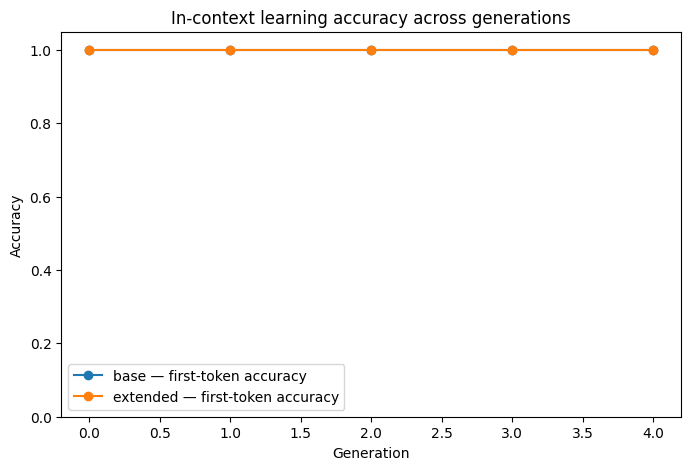

In [14]:

plt.figure(figsize=(8, 5))

for task, group in combined_results.groupby("task"):
    plt.plot(
        group["generation"],
        group["first_token_accuracy"],
        marker="o",
        label=f"{task} — first-token accuracy",
    )

plt.xlabel("Generation")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("In-context learning accuracy across generations")
plt.legend()
plt.show()


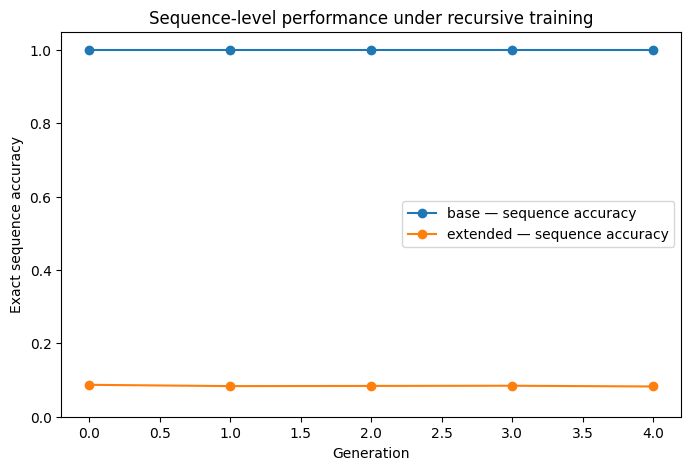

In [15]:

plt.figure(figsize=(8, 5))

for task, group in combined_results.groupby("task"):
    plt.plot(
        group["generation"],
        group["sequence_accuracy"],
        marker="o",
        label=f"{task} — sequence accuracy",
    )

plt.xlabel("Generation")
plt.ylabel("Exact sequence accuracy")
plt.ylim(0, 1.05)
plt.title("Sequence-level performance under recursive training")
plt.legend()
plt.show()


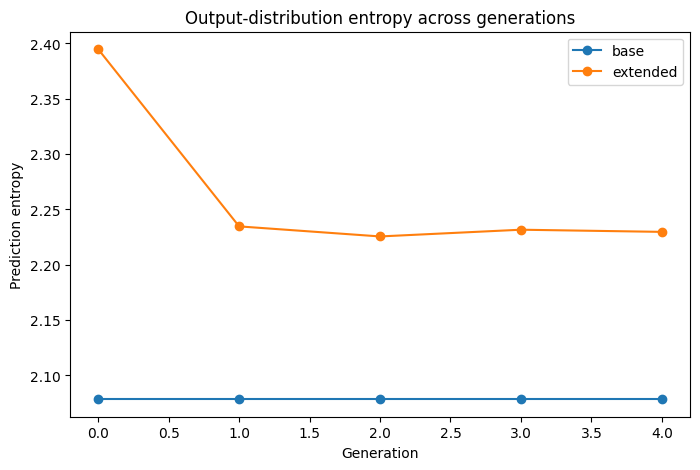

In [16]:

plt.figure(figsize=(8, 5))

for task, group in combined_results.groupby("task"):
    plt.plot(
        group["generation"],
        group["prediction_entropy"],
        marker="o",
        label=task,
    )

plt.xlabel("Generation")
plt.ylabel("Prediction entropy")
plt.title("Output-distribution entropy across generations")
plt.legend()
plt.show()



## 2.6 Save the Part 1–2 results

The CSV below is convenient for the later results/report stage.


In [17]:

combined_results.to_csv(
    "parts_1_2_generation_metrics.csv",
    index=False
)

print("Saved: parts_1_2_generation_metrics.csv")


Saved: parts_1_2_generation_metrics.csv


# NLP Project 1 — Steps 3 and 4
## Performance Analysis and Mechanistic Interpretation

This notebook continues directly from **NLP_Project_Parts_1_and_2.ipynb**.

It implements the brief's:

- **Step 3:** analyse model performance over training/generations using train/validation loss, accuracy, final test accuracy, perplexity, and additional collapse diagnostics.
- **Step 4:** apply mechanistic-interpretability techniques using embeddings, attention maps, quantitative previous-token/induction scores, and causal head ablation.

> **Important:** Run Parts 1–2 first in the same kernel, or run the setup/model/training cells from that notebook before this one. This notebook deliberately does not retrain the entire experiment automatically because that can take substantial time.

## 0. Check that Parts 1–2 are available

The following objects should exist after the earlier notebook has run: `base_experiment`, `extended_experiment`, `base_results`, `extended_results`, `combined_results`, `TaskConfig`, `ICLEpisodeDataset`, `TinyTransformer`, `evaluate`, `collate_batch`, and `DEVICE`.

In [18]:
required_names = [
    "base_experiment", "extended_experiment",
    "base_results", "extended_results", "combined_results",
    "TaskConfig", "ICLEpisodeDataset", "TinyTransformer",
    "evaluate", "collate_batch", "DEVICE"
]
missing = [name for name in required_names if name not in globals()]

if missing:
    raise RuntimeError(
        "Run NLP_Project_Parts_1_and_2.ipynb first in the same kernel. "
        f"Missing objects: {missing}"
    )
else:
    print("Parts 1–2 objects found. Ready for Steps 3 and 4.")

Parts 1–2 objects found. Ready for Steps 3 and 4.


# Step 3 — Analyse performance over training and recursive generations

The brief suggests train loss, validation loss, train/validation accuracy, final test accuracy and perplexity. The earlier notebook also records token accuracy, exact-sequence accuracy and prediction entropy. Together these let us separate **in-context retrieval failure** from broader **distributional collapse**.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

# Keep the combined table ordered and easy to inspect.
combined_results = pd.concat(
    [base_experiment["results"], extended_experiment["results"]],
    ignore_index=True
).sort_values(["task", "generation"])

display(combined_results.round(4))

,task,generation,synthetic_fraction,loss,perplexity,first_token_accuracy,token_accuracy,sequence_accuracy,prediction_entropy
0,base,0,0.00,0.0027,1.0027,1.0,1.0000,1.0000,2.0785
1,base,1,0.25,0.0031,1.0031,1.0,1.0000,1.0000,2.0785
2,base,2,0.50,0.0031,1.0031,1.0,1.0000,1.0000,2.0785
3,base,3,0.75,0.0030,1.0030,1.0,1.0000,1.0000,2.0785
4,base,4,1.00,0.0027,1.0027,1.0,1.0000,1.0000,2.0785
5,extended,0,0.00,0.9433,2.5685,1.0,0.4168,0.0870,2.3948
6,extended,1,0.25,0.9604,2.6127,1.0,0.4145,0.0835,2.2347
7,extended,2,0.50,1.0956,2.9910,1.0,0.4133,0.0840,2.2256
8,extended,3,0.75,1.3129,3.7170,1.0,0.4142,0.0845,2.2317
9,extended,4,1.00,2.8807,17.8274,1.0,0.4135,0.0825,2.2297


## 3.1 Training and validation curves

These curves check whether each generation trained successfully and whether validation loss diverged from training loss.

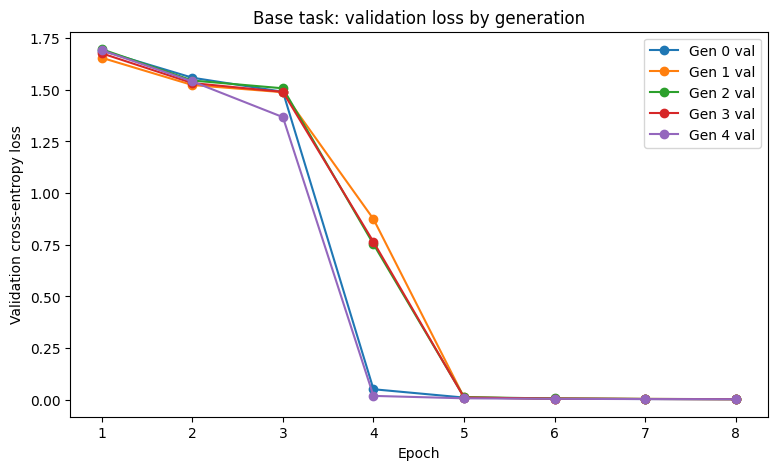

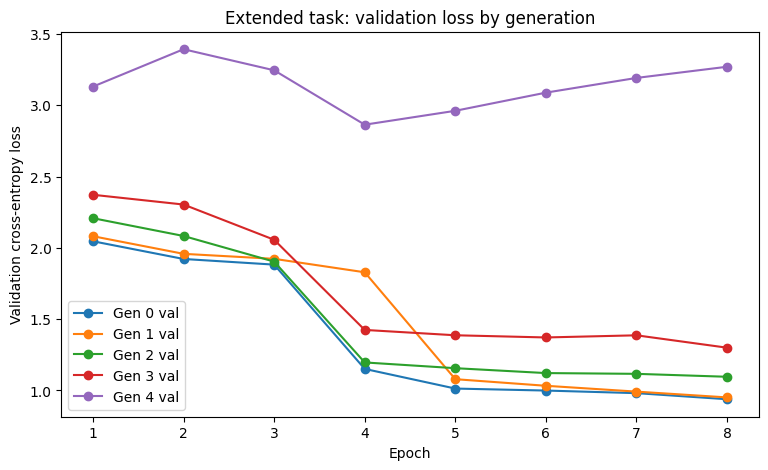

In [20]:
def plot_training_history(experiment, task_name):
    plt.figure(figsize=(9, 5))
    for generation, hist in experiment["histories"].items():
        plt.plot(hist["epoch"], hist["val_loss"], marker="o", label=f"Gen {generation} val")
    plt.xlabel("Epoch")
    plt.ylabel("Validation cross-entropy loss")
    plt.title(f"{task_name.capitalize()} task: validation loss by generation")
    plt.legend()
    plt.show()

plot_training_history(base_experiment, "base")
plot_training_history(extended_experiment, "extended")

## 3.2 Accuracy across generations

For both tasks, **first-token accuracy** measures the original induction problem: can the model retrieve the correct label for the query symbol? For the extended task, **sequence accuracy** is stricter because all three generated tokens must be correct.

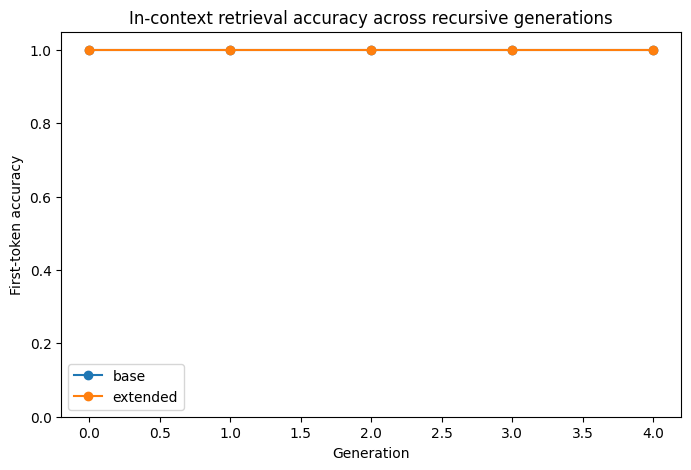

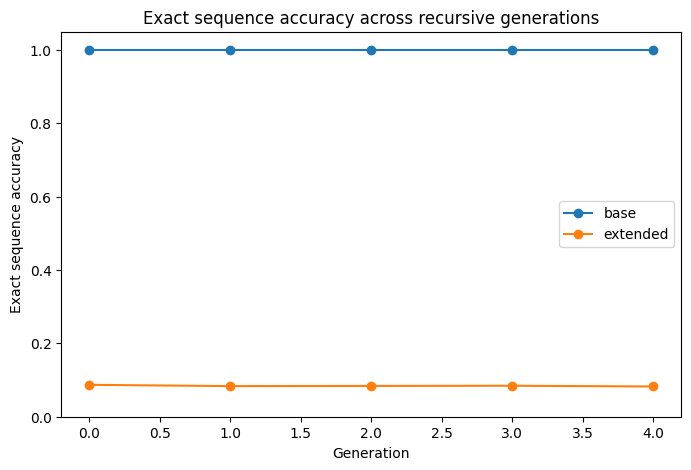

In [21]:
plt.figure(figsize=(8, 5))
for task, group in combined_results.groupby("task"):
    plt.plot(group["generation"], group["first_token_accuracy"], marker="o", label=task)
plt.xlabel("Generation")
plt.ylabel("First-token accuracy")
plt.ylim(0, 1.05)
plt.title("In-context retrieval accuracy across recursive generations")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
for task, group in combined_results.groupby("task"):
    plt.plot(group["generation"], group["sequence_accuracy"], marker="o", label=task)
plt.xlabel("Generation")
plt.ylabel("Exact sequence accuracy")
plt.ylim(0, 1.05)
plt.title("Exact sequence accuracy across recursive generations")
plt.legend()
plt.show()

## 3.3 Loss and perplexity

Perplexity is computed as \(\exp(\mathcal{L})\). Increasing test loss/perplexity across generations is evidence that recursive training is reducing predictive quality on the fixed real test distribution.

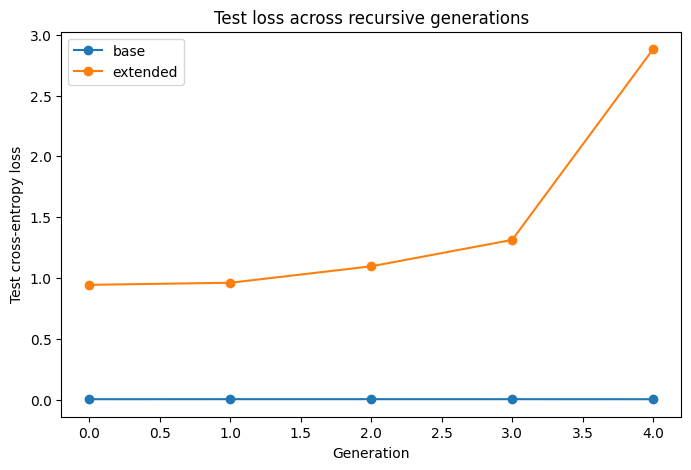

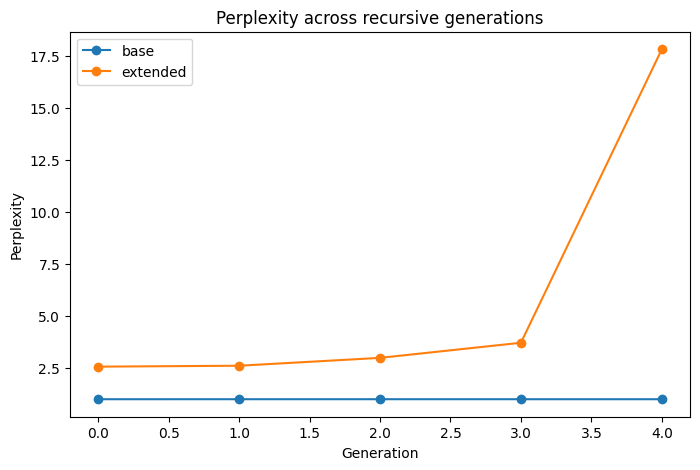

In [22]:
plt.figure(figsize=(8, 5))
for task, group in combined_results.groupby("task"):
    plt.plot(group["generation"], group["loss"], marker="o", label=task)
plt.xlabel("Generation")
plt.ylabel("Test cross-entropy loss")
plt.title("Test loss across recursive generations")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
for task, group in combined_results.groupby("task"):
    plt.plot(group["generation"], group["perplexity"], marker="o", label=task)
plt.xlabel("Generation")
plt.ylabel("Perplexity")
plt.title("Perplexity across recursive generations")
plt.legend()
plt.show()

## 3.4 Prediction entropy as a collapse diagnostic

A falling output entropy can indicate that the model's predictions are concentrating on a smaller subset of tokens. It should be interpreted together with accuracy and loss, not by itself.

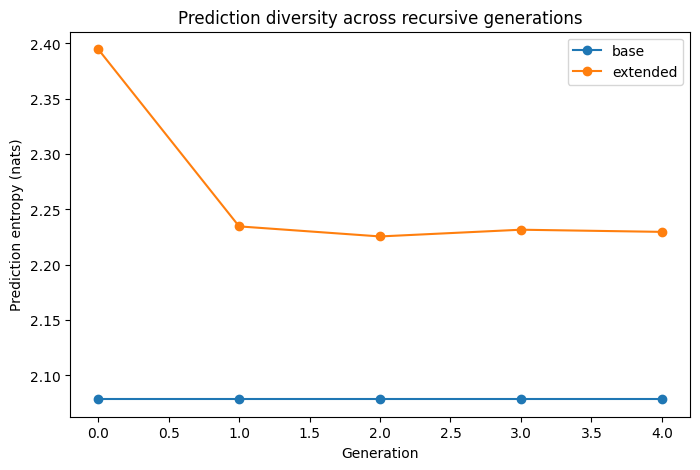

In [23]:
plt.figure(figsize=(8, 5))
for task, group in combined_results.groupby("task"):
    plt.plot(group["generation"], group["prediction_entropy"], marker="o", label=task)
plt.xlabel("Generation")
plt.ylabel("Prediction entropy (nats)")
plt.title("Prediction diversity across recursive generations")
plt.legend()
plt.show()

## 3.5 Quantify degradation from Generation 0

This table expresses later-generation performance relative to the original model. Negative accuracy deltas and positive loss/perplexity deltas indicate degradation.

In [24]:
def degradation_table(results):
    rows = []
    for task, group in results.groupby("task"):
        group = group.sort_values("generation")
        g0 = group.iloc[0]
        for _, row in group.iterrows():
            rows.append({
                "task": task,
                "generation": int(row["generation"]),
                "synthetic_fraction": row["synthetic_fraction"],
                "delta_first_token_accuracy": row["first_token_accuracy"] - g0["first_token_accuracy"],
                "delta_sequence_accuracy": row["sequence_accuracy"] - g0["sequence_accuracy"],
                "delta_loss": row["loss"] - g0["loss"],
                "delta_perplexity": row["perplexity"] - g0["perplexity"],
                "delta_entropy": row["prediction_entropy"] - g0["prediction_entropy"],
            })
    return pd.DataFrame(rows)

degradation = degradation_table(combined_results)
display(degradation.round(4))

,task,generation,synthetic_fraction,delta_first_token_accuracy,delta_sequence_accuracy,delta_loss,delta_perplexity,delta_entropy
0,base,0,0.00,0.0,0.0000,0.0000,0.0000,0.0000
1,base,1,0.25,0.0,0.0000,0.0004,0.0004,0.0000
2,base,2,0.50,0.0,0.0000,0.0004,0.0004,0.0000
3,base,3,0.75,0.0,0.0000,0.0002,0.0002,0.0000
4,base,4,1.00,0.0,0.0000,-0.0001,-0.0001,0.0000
5,extended,0,0.00,0.0,0.0000,0.0000,0.0000,0.0000
6,extended,1,0.25,0.0,-0.0035,0.0171,0.0442,-0.1601
7,extended,2,0.50,0.0,-0.0030,0.1523,0.4225,-0.1692
8,extended,3,0.75,0.0,-0.0025,0.3696,1.1484,-0.1631
9,extended,4,1.00,0.0,-0.0045,1.9374,15.2588,-0.1651


## 3.6 Save Step 3 tables

In [25]:
combined_results.to_csv("step3_generation_metrics.csv", index=False)
degradation.to_csv("step3_degradation_from_gen0.csv", index=False)
print("Saved Step 3 CSV files.")

Saved Step 3 CSV files.


# Step 4 — Mechanistic interpretation

The goal is to test whether the transformer develops attention behaviour consistent with the circuit described in the brief:

1. a **previous-token head**, which attends one position back; and
2. an **induction/retrieval head**, where the query retrieves information associated with an earlier occurrence of the same symbol.

Attention visualisation is descriptive. We therefore add **head ablation** as a causal test: if disabling a head substantially reduces accuracy, that head is functionally important.

## 4.1 Inspect learned token embeddings

A simple PCA projection gives a qualitative view of whether symbol tokens and label tokens form different geometric structures.

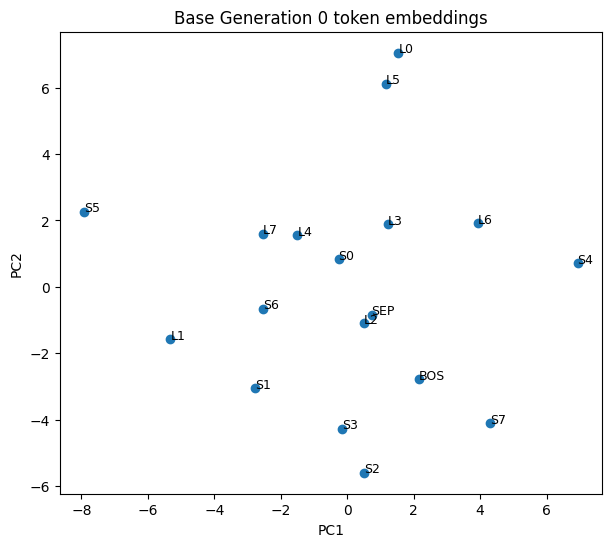

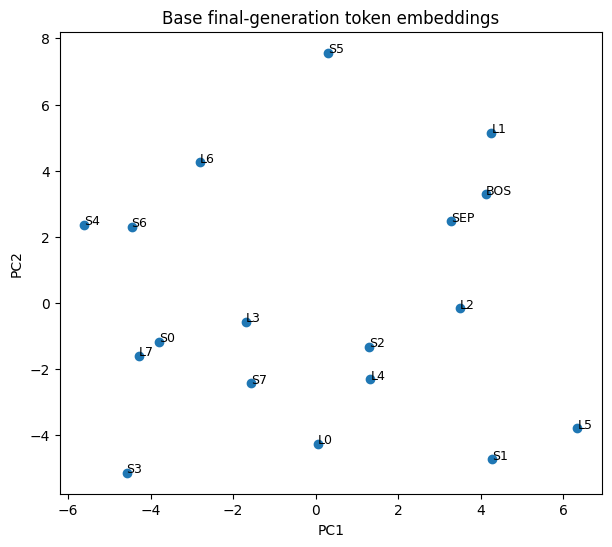

In [26]:
def pca_2d(x):
    x = x - x.mean(axis=0, keepdims=True)
    _, _, vt = np.linalg.svd(x, full_matrices=False)
    return x @ vt[:2].T

def plot_embeddings(model, cfg, title):
    emb = model.token_embedding.weight.detach().cpu().numpy()
    xy = pca_2d(emb)
    labels = []
    for token_id in range(cfg.vocab_size):
        if token_id < cfg.n_symbols:
            labels.append(f"S{token_id}")
        elif token_id < cfg.n_symbols + cfg.n_labels:
            labels.append(f"L{token_id-cfg.label_offset}")
        elif token_id == cfg.bos_id:
            labels.append("BOS")
        else:
            labels.append("SEP")
    plt.figure(figsize=(7, 6))
    plt.scatter(xy[:, 0], xy[:, 1])
    for i, label in enumerate(labels):
        plt.annotate(label, (xy[i, 0], xy[i, 1]), fontsize=9)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(title)
    plt.show()

base_cfg = TaskConfig(mode="base")
plot_embeddings(base_experiment["models"][0], base_cfg, "Base Generation 0 token embeddings")
plot_embeddings(base_experiment["models"][max(base_experiment["models"])], base_cfg, "Base final-generation token embeddings")

## 4.2 Extract and plot attention maps

`CausalSelfAttention` from Parts 1–2 stores `last_attn`, so a normal forward pass gives a matrix for every layer and head.

Example metadata: {'mapping': {0: 5, 1: 4, 2: 6, 3: 0, 4: 2, 5: 1, 6: 3, 7: 7}, 'context_symbols': [3, 5, 1, 3, 2, 6], 'query_symbol': 2, 'query_label': 6, 'next_symbol': 2, 'next_label': 6}


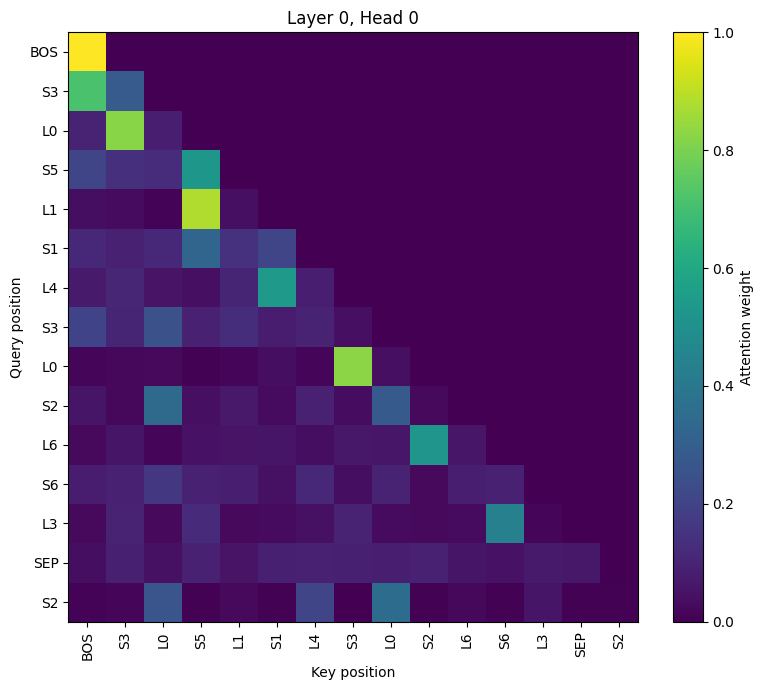

In [27]:
def token_names(prompt, cfg):
    names = []
    for token_id in prompt.tolist():
        if token_id < cfg.n_symbols:
            names.append(f"S{token_id}")
        elif token_id < cfg.n_symbols + cfg.n_labels:
            names.append(f"L{token_id-cfg.label_offset}")
        elif token_id == cfg.bos_id:
            names.append("BOS")
        elif token_id == cfg.sep_id:
            names.append("SEP")
        else:
            names.append(str(token_id))
    return names

@torch.no_grad()
def collect_attention(model, prompt):
    model.eval()
    _ = model(prompt.unsqueeze(0).to(DEVICE))
    return [block.attn.last_attn[0].cpu() for block in model.blocks]

def plot_attention_head(model, prompt, cfg, layer=0, head=0, title=None):
    attn_layers = collect_attention(model, prompt)
    matrix = attn_layers[layer][head].numpy()
    names = token_names(prompt, cfg)
    plt.figure(figsize=(8, 7))
    plt.imshow(matrix, aspect="auto")
    plt.colorbar(label="Attention weight")
    plt.xticks(range(len(names)), names, rotation=90)
    plt.yticks(range(len(names)), names)
    plt.xlabel("Key position")
    plt.ylabel("Query position")
    plt.title(title or f"Layer {layer}, Head {head}")
    plt.tight_layout()
    plt.show()

example_prompt, _, example_meta = base_experiment["test_dataset"][0]
print("Example metadata:", example_meta)
plot_attention_head(base_experiment["models"][0], example_prompt, base_cfg, layer=0, head=0)

## 4.3 Previous-token score

For each head, compute the mean attention weight assigned to position \(t-1\) from position \(t\). A high value indicates previous-token-like behaviour.

In [28]:
@torch.no_grad()
def previous_token_scores(model, dataset, n_examples=300):
    n_examples = min(n_examples, len(dataset))
    sums = None
    count = 0
    model.eval()

    for i in range(n_examples):
        prompt, _, _ = dataset[i]
        attn_layers = collect_attention(model, prompt)
        layer_scores = []
        for attn in attn_layers:
            # attn shape: [heads, T, T]
            T = attn.shape[-1]
            idx = torch.arange(1, T)
            score = attn[:, idx, idx - 1].mean(dim=1)
            layer_scores.append(score)
        stacked = torch.stack(layer_scores)  # [layers, heads]
        sums = stacked if sums is None else sums + stacked
        count += 1

    return sums / count

def score_matrix_to_df(scores, metric_name):
    rows = []
    for layer in range(scores.shape[0]):
        for head in range(scores.shape[1]):
            rows.append({"layer": layer, "head": head, metric_name: float(scores[layer, head])})
    return pd.DataFrame(rows).sort_values(metric_name, ascending=False)

prev_scores_g0 = previous_token_scores(
    base_experiment["models"][0], base_experiment["test_dataset"]
)
prev_df_g0 = score_matrix_to_df(prev_scores_g0, "previous_token_score")
display(prev_df_g0.round(4))

,layer,head,previous_token_score
1,0,1,0.5351
3,0,3,0.4757
2,0,2,0.4666
0,0,0,0.4085
7,1,3,0.1752
6,1,2,0.1695
4,1,0,0.1643
5,1,1,0.1556


## 4.4 Induction/retrieval score

The prompt ends with `SEP, query_symbol`. For each episode, locate previous occurrences of the query symbol in the context and measure how strongly the final query position attends to the **label immediately after those matching symbols**. This is a practical retrieval score for this implementation.

In [29]:
@torch.no_grad()
def induction_scores(model, dataset, cfg, n_examples=300):
    n_examples = min(n_examples, len(dataset))
    sums = None
    count = 0
    model.eval()

    for i in range(n_examples):
        prompt, _, meta = dataset[i]
        query_symbol = meta["query_symbol"]
        # Symbol positions in our prompt are 1,3,5,...
        matching_label_positions = []
        for pair_idx, s in enumerate(meta["context_symbols"]):
            if s == query_symbol:
                symbol_pos = 1 + 2 * pair_idx
                matching_label_positions.append(symbol_pos + 1)

        if not matching_label_positions:
            continue

        attn_layers = collect_attention(model, prompt)
        query_pos = len(prompt) - 1
        layer_scores = []
        for attn in attn_layers:
            # Sum attention to labels following matching earlier symbols.
            score = attn[:, query_pos, matching_label_positions].sum(dim=1)
            layer_scores.append(score)
        stacked = torch.stack(layer_scores)
        sums = stacked if sums is None else sums + stacked
        count += 1

    return sums / max(count, 1)

ind_scores_g0 = induction_scores(
    base_experiment["models"][0],
    base_experiment["test_dataset"],
    base_cfg
)
ind_df_g0 = score_matrix_to_df(ind_scores_g0, "induction_score")
display(ind_df_g0.round(4))

,layer,head,induction_score
7,1,3,0.9870
5,1,1,0.9707
4,1,0,0.9700
6,1,2,0.9400
3,0,3,0.2486
0,0,0,0.2483
2,0,2,0.2373
1,0,1,0.1938


## 4.5 Track circuit scores across model-collapse generations

This tests whether candidate attention behaviours weaken, strengthen or migrate to different heads as recursive training increases.

In [30]:
def circuit_scores_across_generations(experiment, cfg, n_examples=300):
    rows = []
    dataset = experiment["test_dataset"]
    for generation, model in experiment["models"].items():
        prev = previous_token_scores(model, dataset, n_examples)
        ind = induction_scores(model, dataset, cfg, n_examples)
        for layer in range(prev.shape[0]):
            for head in range(prev.shape[1]):
                rows.append({
                    "generation": generation,
                    "layer": layer,
                    "head": head,
                    "previous_token_score": float(prev[layer, head]),
                    "induction_score": float(ind[layer, head]),
                })
    return pd.DataFrame(rows)

base_circuit_scores = circuit_scores_across_generations(
    base_experiment, base_cfg
)
display(base_circuit_scores.round(4))

,generation,layer,head,previous_token_score,induction_score
0,0,0,0,0.4085,0.2483
1,0,0,1,0.5351,0.1938
2,0,0,2,0.4666,0.2373
3,0,0,3,0.4757,0.2486
4,0,1,0,0.1643,0.9700
5,0,1,1,0.1556,0.9707
6,0,1,2,0.1695,0.9400
7,0,1,3,0.1752,0.9870
8,1,0,0,0.3013,0.2322
9,1,0,1,0.4972,0.1996


Strongest Generation-0 retrieval candidate: Layer 1, Head 3


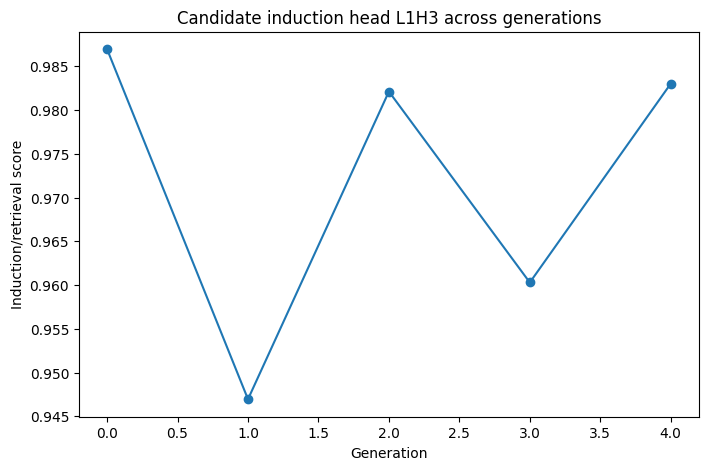

In [31]:
# Plot the strongest Generation-0 induction head across generations.
best = base_circuit_scores[base_circuit_scores["generation"] == 0].sort_values(
    "induction_score", ascending=False
).iloc[0]
best_layer, best_head = int(best["layer"]), int(best["head"])

track = base_circuit_scores[
    (base_circuit_scores["layer"] == best_layer) &
    (base_circuit_scores["head"] == best_head)
].sort_values("generation")

print(f"Strongest Generation-0 retrieval candidate: Layer {best_layer}, Head {best_head}")
plt.figure(figsize=(8, 5))
plt.plot(track["generation"], track["induction_score"], marker="o")
plt.xlabel("Generation")
plt.ylabel("Induction/retrieval score")
plt.title(f"Candidate induction head L{best_layer}H{best_head} across generations")
plt.show()

## 4.6 Causal head ablation

Attention maps do not prove that a head is necessary. The following helper temporarily forces a selected head's output to zero and measures the change in test accuracy. Larger accuracy drops indicate greater causal importance.

In [32]:
def install_head_ablation(model, layer_idx, head_idx):
    attn_module = model.blocks[layer_idx].attn
    original_forward = attn_module.forward

    def ablated_forward(x):
        B, T, C = x.shape
        qkv = attn_module.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)
        q = q.view(B, T, attn_module.n_heads, attn_module.head_dim).transpose(1, 2)
        k = k.view(B, T, attn_module.n_heads, attn_module.head_dim).transpose(1, 2)
        v = v.view(B, T, attn_module.n_heads, attn_module.head_dim).transpose(1, 2)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(attn_module.head_dim)
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(mask, float("-inf"))
        attn = torch.softmax(scores, dim=-1)
        attn_module.last_attn = attn.detach()
        y = attn_module.dropout(attn) @ v
        y[:, head_idx, :, :] = 0.0
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return attn_module.out(y)

    attn_module.forward = ablated_forward
    return attn_module, original_forward

def restore_head(attn_module, original_forward):
    attn_module.forward = original_forward

@torch.no_grad()
def head_ablation_table(model, dataset, batch_size=256):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_batch)
    baseline = evaluate(model, loader, DEVICE)
    rows = []
    for layer_idx, block in enumerate(model.blocks):
        for head_idx in range(block.attn.n_heads):
            module, original = install_head_ablation(model, layer_idx, head_idx)
            metrics = evaluate(model, loader, DEVICE)
            restore_head(module, original)
            rows.append({
                "layer": layer_idx,
                "head": head_idx,
                "baseline_first_token_accuracy": baseline["first_token_accuracy"],
                "ablated_first_token_accuracy": metrics["first_token_accuracy"],
                "accuracy_drop": baseline["first_token_accuracy"] - metrics["first_token_accuracy"],
                "baseline_loss": baseline["loss"],
                "ablated_loss": metrics["loss"],
                "loss_increase": metrics["loss"] - baseline["loss"],
            })
    return pd.DataFrame(rows).sort_values("accuracy_drop", ascending=False)

ablation_g0 = head_ablation_table(
    base_experiment["models"][0],
    base_experiment["test_dataset"]
)
display(ablation_g0.round(4))

,layer,head,baseline_first_token_accuracy,ablated_first_token_accuracy,accuracy_drop,baseline_loss,ablated_loss,loss_increase
0,0,0,1.0,1.0,0.0,0.0027,0.0027,-0.0000
1,0,1,1.0,1.0,0.0,0.0027,0.0056,0.0028
2,0,2,1.0,1.0,0.0,0.0027,0.0027,-0.0000
3,0,3,1.0,1.0,0.0,0.0027,0.0027,-0.0000
4,1,0,1.0,1.0,0.0,0.0027,0.0049,0.0022
5,1,1,1.0,1.0,0.0,0.0027,0.0046,0.0018
6,1,2,1.0,1.0,0.0,0.0027,0.0038,0.0011
7,1,3,1.0,1.0,0.0,0.0027,0.0057,0.0030


## 4.7 Combine attention evidence and causal evidence

A strong candidate induction head should ideally show: (i) a high retrieval score, and (ii) a meaningful performance drop when ablated. A high attention score without an ablation effect should be described cautiously.

In [33]:
mechanistic_summary_g0 = (
    prev_df_g0.merge(ind_df_g0, on=["layer", "head"])
    .merge(ablation_g0[["layer", "head", "accuracy_drop", "loss_increase"]], on=["layer", "head"])
    .sort_values(["induction_score", "accuracy_drop"], ascending=False)
)
display(mechanistic_summary_g0.round(4))

mechanistic_summary_g0.to_csv("step4_gen0_head_summary.csv", index=False)
base_circuit_scores.to_csv("step4_circuit_scores_across_generations.csv", index=False)
print("Saved Step 4 CSV files.")

,layer,head,previous_token_score,induction_score,accuracy_drop,loss_increase
4,1,3,0.1752,0.9870,0.0,0.0030
7,1,1,0.1556,0.9707,0.0,0.0018
6,1,0,0.1643,0.9700,0.0,0.0022
5,1,2,0.1695,0.9400,0.0,0.0011
1,0,3,0.4757,0.2486,0.0,-0.0000
3,0,0,0.4085,0.2483,0.0,-0.0000
2,0,2,0.4666,0.2373,0.0,-0.0000
0,0,1,0.5351,0.1938,0.0,0.0028


Saved Step 4 CSV files.


## 4.8 Interpretation guide for your report

Use the observed results rather than assuming collapse must occur. Examples of defensible interpretations are:

- **Accuracy decreases and induction score decreases:** recursive training is associated with both behavioural degradation and weakening of the retrieval mechanism.
- **Accuracy decreases but the induction score remains stable:** the induction-like attention pattern persists, so degradation may arise elsewhere in the computation.
- **The strongest head changes across generations:** the circuit may be reorganising rather than simply disappearing.
- **A high-scoring head causes a large ablation drop:** this provides stronger evidence that the head contributes causally to the task.
- **Attention looks interpretable but ablation has little effect:** do not claim that the head is necessary; the model may have redundant or distributed mechanisms.

These measurements are proxies for the circuit described in the project brief. A full circuit-level causal analysis would require additional interventions, so state this limitation explicitly.